# Three cities, one method — Lamudi's Pakistan footprint

**Companion notebook for [_Why invest in Lahore real-estate_](https://ilm.red/blog/why-invest-in-lahore-real-estate) on ilm.red.**

The article argues that Pakistani property data is opaque, so an investor must reason from a
city's *structure* rather than from clean price series. This notebook does exactly that with the
one dataset anyone can verify in a browser: the live listing counts that **Lamudi.pk** — a
national property portal headquartered, fittingly, in **Gulberg, Lahore** — publishes on its own
homepage for Islamabad, Lahore and Karachi.

Three honesty rules, inherited from the article:

1. **Counts are not prices.** A listing count measures supply and portal adoption, not value.
2. **Asking is not selling.** Nothing on any Pakistani portal is a closed transaction.
3. **One portal is one witness.** Lamudi is a real but partial view; cross-check against others
   (Zameen, Graana) before believing any level. The *shape* is what we trust, not the level.


## 1 · The footprint snapshot (recorded 2026-08-25)

These numbers were read from [lamudi.pk](https://www.lamudi.pk/) on 2026-08-25 — each is the
count the site itself prints next to its category links (e.g. *"Houses for Sale in Lahore
(22291)"*). They are reproducible: open the homepage and count along.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Observed on https://www.lamudi.pk/ — 2026-08-25. Each value appears verbatim on the page.
SNAPSHOT_DATE = "2026-08-25"
SNAPSHOT = {
    "category":  ["houses", "residential_plots", "flats", "commercial_plots", "shops", "offices"],
    "Lahore":    [22291, 30047, 3706, 4110, 597, 219],
    "Karachi":   [11845, 10704, 11946, 918, 1019, 761],
    "Islamabad": [9765, 27748, 4058, 1543, 1754, 436],
}
snap = pd.DataFrame(SNAPSHOT).set_index("category")
snap["source"] = "https://www.lamudi.pk/ (homepage category counts)"
snap[["Lahore", "Karachi", "Islamabad"]]

,Lahore,Karachi,Islamabad
category,,,
houses,22291,11845,9765
residential_plots,30047,10704,27748
flats,3706,11946,4058
commercial_plots,4110,918,1543
shops,597,1019,1754
offices,219,761,436


## 2 · Refresh it live (this is the "run it yourself")

This cell re-reads the homepage and parses today's counts. When it cannot reach the site (no
network, or the page changed shape) it says so and falls back to the recorded snapshot — a
failed fetch must never silently impersonate a measurement.


In [2]:
import re, urllib.request

CITY_RE = re.compile(
    r'(Houses|Residential Plots|Flats|Commercial Plots|Shops|Offices) for Sale in '
    r'(Lahore|Karachi|Islamabad)\s*\((\d+)\)', re.I)
CAT_KEY = {"houses": "houses", "residential plots": "residential_plots", "flats": "flats",
           "commercial plots": "commercial_plots", "shops": "shops", "offices": "offices"}

def fetch_live_counts(timeout=20):
    req = urllib.request.Request("https://www.lamudi.pk/", headers={"User-Agent": "Mozilla/5.0"})
    html = urllib.request.urlopen(req, timeout=timeout).read().decode("utf-8", "replace")
    out = {}
    for cat, city, n in CITY_RE.findall(html):
        out.setdefault(CAT_KEY[cat.lower()], {})[city.title()] = int(n)
    if not out:
        raise ValueError("page fetched but no counts matched — the homepage layout changed")
    return out

try:
    live = fetch_live_counts()
    counts = pd.DataFrame(live).T.reindex(snap.index)[["Lahore", "Karachi", "Islamabad"]]
    counts_date = pd.Timestamp.today().strftime("%Y-%m-%d")
    print(f"live counts fetched {counts_date}")
except Exception as e:
    counts = snap[["Lahore", "Karachi", "Islamabad"]].copy()
    counts_date = SNAPSHOT_DATE
    print(f"live fetch unavailable ({type(e).__name__}) — using the recorded {SNAPSHOT_DATE} snapshot")
counts

live fetch unavailable (URLError) — using the recorded 2026-08-25 snapshot


,Lahore,Karachi,Islamabad
category,,,
houses,22291,11845,9765
residential_plots,30047,10704,27748
flats,3706,11946,4058
commercial_plots,4110,918,1543
shops,597,1019,1754
offices,219,761,436


## 3 · What the composition says (this is the article's argument, in numbers)

Levels depend on portal adoption; *composition* is harder to fake. Three structural readings:

- **Plots-to-houses ratio** — how much of a city's market is bets on land that has no building
  on it yet. The article calls this the speculative frontier.
- **Flats share of homes** — verticality: homes people rent and occupy densely.
- **Commercial per 1,000 homes** — how much shop/office life the portal sees beside the housing.


In [3]:
cities = ["Lahore", "Karachi", "Islamabad"]
homes = counts.loc["houses"] + counts.loc["flats"]
structure = pd.DataFrame({
    "plots_per_house":  (counts.loc["residential_plots"] / counts.loc["houses"]).round(2),
    "flats_share_of_homes": (counts.loc["flats"] / homes).round(2),
    "commercial_per_1k_homes": (1000 * (counts.loc["commercial_plots"] + counts.loc["shops"]
                                        + counts.loc["offices"]) / homes).round(0),
})
structure

,plots_per_house,flats_share_of_homes,commercial_per_1k_homes
Lahore,1.35,0.14,189.0
Karachi,0.90,0.50,113.0
Islamabad,2.84,0.29,270.0


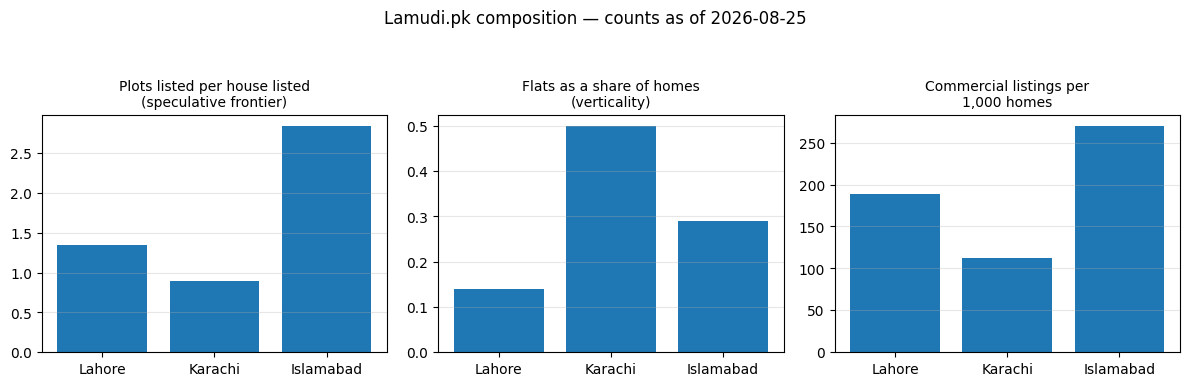

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (col, title) in zip(axes, [
    ("plots_per_house", "Plots listed per house listed\n(speculative frontier)"),
    ("flats_share_of_homes", "Flats as a share of homes\n(verticality)"),
    ("commercial_per_1k_homes", "Commercial listings per\n1,000 homes"),
]):
    ax.bar(cities, structure.loc[cities, col].values)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", alpha=0.3)
fig.suptitle(f"Lamudi.pk composition — counts as of {counts_date}", y=1.06)
plt.tight_layout(); plt.show()

Read against the article's thesis, from the recorded snapshot:

- **Islamabad lists ~2.8 plots for every house** — by far the highest of the three. The planned
  city's market is dominated by paper: sectors that exist as files (B-17, D-18, the Gulberg of
  Islamabad) before they exist as streets. That is the "creature of the state" pattern.
- **Karachi's flats share (~50%) dwarfs Lahore's (~14%) and Islamabad's (~29%)** — the port
  megacity builds up, and its rental stock looks like it.
- **Lahore leads houses and commercial plots outright** — horizontal, mixed-use, lived-in
  inventory. This is the "grown city" signature the article bets on: things standing on land,
  with commerce beside them, rather than files about land.

None of this prices anything. It is the *shape* of three markets, from one honest witness.


## 4 · Toward a real forecast — collect first, then extrapolate

One snapshot cannot forecast. The honest path: **run this notebook on a schedule** — the cell
below appends today's counts to `lamudi_series.csv`; six weekly rows make a series worth
fitting.


In [5]:
from pathlib import Path
SERIES = Path("lamudi_series.csv")
row = counts[cities].T.assign(date=counts_date).reset_index(names="city")
if SERIES.exists():
    hist = pd.read_csv(SERIES)
    hist = pd.concat([hist[hist["date"] != counts_date], row])
else:
    hist = row
hist.to_csv(SERIES, index=False)
print(f"{SERIES}: {hist['date'].nunique()} dated observation(s) for {hist['city'].nunique()} cities")

lamudi_series.csv: 1 dated observation(s) for 3 cities


### The forecasting method, demonstrated on labelled stand-in data

Until the CSV has real depth, the method runs on a **clearly synthetic** series so the mechanics
are visible. **Every number below this line is invented for demonstration** — the trend levels
are made up; only the *method* (least-squares trend + a residual band, per city) transfers. The
moment `lamudi_series.csv` holds six or more real dates, the same cell fits those instead and
the caveat retires itself.


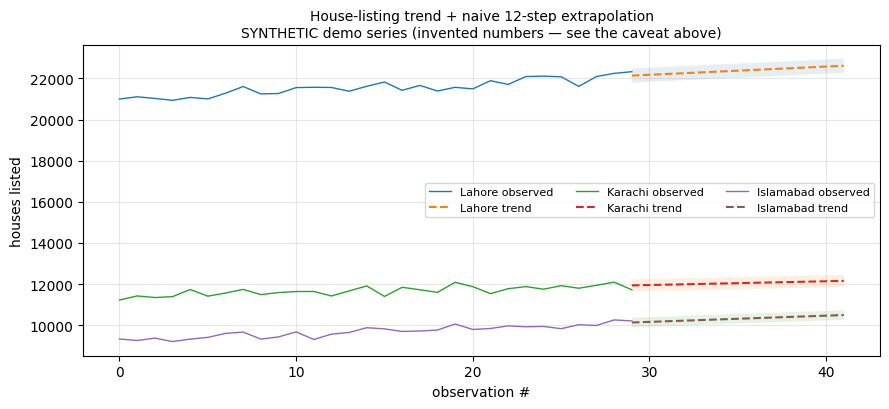

In [6]:
import numpy as np
rng = np.random.default_rng(7)

real = hist.groupby("city").size().min() if len(hist) else 0
if hist["date"].nunique() >= 6:
    fit = hist.pivot_table(index="date", columns="city", values="houses")
    label = "REAL series from lamudi_series.csv"
else:
    weeks = pd.date_range("2026-01-05", periods=30, freq="W")
    fit = pd.DataFrame({   # SYNTHETIC: levels and slopes are invented for the demo
        "Lahore":    21000 + 45 * np.arange(30) + rng.normal(0, 220, 30),
        "Karachi":   11500 + 12 * np.arange(30) + rng.normal(0, 180, 30),
        "Islamabad": 9300 + 28 * np.arange(30) + rng.normal(0, 150, 30),
    }, index=weeks)
    label = "SYNTHETIC demo series (invented numbers — see the caveat above)"

H = 12  # forecast horizon, in observations
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(fit))
xf = np.arange(len(fit) + H)
for city in cities:
    y = fit[city].values
    a, b = np.polyfit(x, y, 1)
    resid = y - (a * x + b)
    band = 1.96 * resid.std()
    yf = a * xf + b
    ax.plot(x, y, lw=1, label=f"{city} observed")
    ax.plot(xf[len(fit)-1:], yf[len(fit)-1:], "--", lw=1.5, label=f"{city} trend")
    ax.fill_between(xf[len(fit)-1:], yf[len(fit)-1:] - band, yf[len(fit)-1:] + band, alpha=0.12)
ax.set_title(f"House-listing trend + naive 12-step extrapolation\n{label}", fontsize=10)
ax.set_ylabel("houses listed"); ax.set_xlabel("observation #")
ax.legend(fontsize=8, ncol=3); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 5 · Limitations, stated the article's way

- **Listing counts confound supply with portal adoption.** A city where Lamudi markets harder
  shows more listings without one extra brick existing.
- **A trend in counts is not a trend in prices**, and a trend in asking prices would still not
  be one in sale prices. Pakistan has no functional MLS; treat every extrapolation here as a
  sketch of *method*, never as advice.
- **Cross-witness before believing a level.** Repeat section 2 against a second portal and keep
  both series; where the witnesses disagree, the disagreement is itself the finding.
- The article's conclusion stands apart from any of this arithmetic: judge a street by its mix,
  its ownership, its movement and its small self-funded improvements — then let numbers argue
  with what your feet saw.
